# Diverse Plots: Wer verdient in den USA wie viel?

**Statistik für Data Science** · Kurs 3,906 · Bachelor Computer Science · HS2026
Universität St. Gallen

---
### Projektteam:
- Andrin Greitmann
- Noah Appenzeller
- Manuel Schmid

---

Dieses Notebook enthält explorative Plots zu unserem Datensatz. Die Plot-Arten stammen aus VL01 und VL02. 

## 0. Setup
Importiert `pandas`, `numpy`, `seaborn` und `matplotlib` und setzt den Seed.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Seed: Startwert für den Zufallsgenerator. Gleicher Seed bei jedem Durchlauf damit Resultate deterministisch & reproduzierbar sind. 
# Den Wert selbst haben wir beliebig gewählt, wir haben ihn als erstes vor der Analyse gewählt und danach nicht mehr geändert.
# Der Seed wird für alles Zufällige in allen Notebooks verwendet.
SEED = 2001
RNG = np.random.default_rng(SEED)

# Plot-Defauls
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7.5, 4.2)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

In [2]:
import sys

print("Python  ", sys.version.split()[0])
for modul in (np, pd, sns):
    print(f"{modul.__name__:8s}", modul.__version__)
print("Seed    ", SEED)

Python   3.14.4
numpy    2.5.3
pandas   3.0.6
seaborn  0.13.2
Seed     2001


### Unseren Datensatz laden

In [3]:
from ucimlrepo import fetch_ucirepo

# Datensatz direkt aus dem UCI Repository laden (ID 117 = Census-Income KDD)
census_income_kdd = fetch_ucirepo(id=117)

# Etwas spezielles an unserem Datenset: ucimlrepo liefert die Daten aufgeteilt in Features und Target. 
# (Wahrscheinlich für Machine Learning Projekte/Algorithmen)
# Target ist das Einkommen (über/unter 50K), Features sind alle anderen Merkmale.
X = census_income_kdd.data.features
y = census_income_kdd.data.targets

# Für die EDA wollten wir alle Spalten in einem DataFrame damit das Einkommen mit den anderen Merkmalen verglichen werden kann.
# join() funktioniert hier zum Glück recht einfach, weil X und y dieselben Zeilen in derselben Reihenfolge haben.
census = X.join(y)
 
# Leerzeichen bei den Textspalten entfernen
text_spalten = census.select_dtypes(exclude="number").columns
census[text_spalten] = census[text_spalten].apply(lambda s: s.str.strip())

# Wir wollen die Spalten umbenennen, sodass es ersichtlicher ist, mit was wir arbeiten
# Dies ist jedoch in den Metadaten der folgenden Ausgabe noch nicht ersichtlich, erst bei allen späteren Ausgaben.

spalten_umbenennung = {
    "AAGE": "AGE", "ACLSWKR": "CLASS_OF_WORKER", "ADTINK": "INDUSTRY_CODE",      
    "ADTOCC": "OCCUPATION_CODE", "AHGA": "EDUCATION", "AHSCOL": "ENROLLED_IN_EDU",
    "AMARITL": "MARITAL_STATUS", "AMJIND": "MAJOR_INDUSTRY", "AMJOCC": "MAJOR_OCCUPATION",
    "ARACE": "RACE", "AREORGN": "HISPANIC_ORIGIN", "ASEX": "SEX",
    "AUNMEM": "LABOR_UNION_MEMBER", "AUNTYPE": "UNEMPLOYMENT_REASON", "AWKSTAT": "EMPLOYMENT_STATUS",
    "CAPGAIN": "CAPITAL_GAINS", "GAPLOSS": "CAPITAL_LOSSES", "DIVVAL": "DIVIDENDS",
    "FILESTAT": "TAX_FILER_STATUS", "GRINREG": "PREV_REGION", "GRINST": "PREV_STATE",
    "HHDFMX": "HOUSEHOLD_STAT_DETAILED", "HHDREL": "HOUSEHOLD_SUMMARY", "MARSUPWRT": "WEIGHT",
    "MIGMTR1": "MIGRATION_MSA", "MIGMTR3": "MIGRATION_REG", "MIGMTR4": "MIGRATION_WITHIN_REG",
    "MIGSAME": "SAME_HOUSE_1YR", "MIGSUN": "MIGRATION_SUNBELT", "NOEMP": "NUM_EMPLOYEES",
    "PARENT": "PARENTS_PRESENT", "PEFNTVTY": "BIRTH_COUNTRY_FATHER", "PEMNTVTY": "BIRTH_COUNTRY_MOTHER",
    "PENATVTY": "BIRTH_COUNTRY_SELF", "PRCITSHP": "CITIZENSHIP", "SEOTR": "SELF_EMPLOYED",
    "VETQVA": "VET_QUESTIONNAIRE", "VETYN": "VETERANS_BENEFITS", "WKSWORK": "WEEKS_WORKED",
    "AHRSPAY": "WAGE_PER_HOUR", "year": "YEAR", "income": "INCOME"
}
census = census.rename(columns=spalten_umbenennung)

# Metadaten: Herkunft, Beschreibung und Erhebung des Datensatzes (Damit wir auf Bias analysieren können)
print("Metadata: " + str(census_income_kdd.metadata))

print(f"Rows: {census.shape[0]}, Columns: {census.shape[1]}")

# Variablenbeschreibung: Name, Typ und Bedeutung jeder Spalte (Grundlage um später Messniveau zu bestimmen)
print("Variable descriptions:")

# display(census_income_kdd.variables)

Metadata: {'uci_id': 117, 'name': 'Census-Income (KDD)', 'repository_url': 'https://archive.ics.uci.edu/dataset/117/census+income+kdd', 'data_url': 'https://archive.ics.uci.edu/static/public/117/data.csv', 'abstract': 'This data set contains weighted census data extracted from the 1994 and 1995 current population surveys conducted by the U.S. Census Bureau.', 'area': 'Social Science', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 299285, 'num_features': 41, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Occupation', 'Education Level', 'Marital Status', 'Race', 'Sex', 'Other', 'Nationality', 'Income'], 'target_col': ['income'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2000, 'last_updated': 'Fri Mar 08 2024', 'dataset_doi': '10.24432/C5N30T', 'creators': [], 'intro_paper': None, 'additional_info': {'summary': "This data set contains weighted census data extracted

### Datensatz bereinigen
Hier wenden wir die Bereinigung aus NB01 (Abschnitt 5) an, inklusive der neuen Spalten aus den originalen CPS-Daten (NB01, 5.1). Danach ist `census` der bereinigte Datensatz, die Rohdaten bleiben als `census_raw` verfügbar.

In [4]:
# Die Abfrage sorgt dafür, dass ein zweites Ausführen dieser Zelle wieder
# bei den Rohdaten startet (sonst würde z.B. der Stundenlohn ein zweites Mal durch 100 geteilt).
if "census_raw" not in globals():
    census_raw = census
census = census_raw.copy()

# 1) Migrationsblock 1995 wurde nicht erhoben, auch wo "Not in universe" steht (3.2)
jahr_95 = census["YEAR"] == 95
census.loc[jahr_95, ["SAME_HOUSE_1YR", "PREV_REGION"]] = np.nan

# 2) Die Bundesstaaten passen nicht zur Region, die Spalte verwenden wir nicht (3.3)
census = census.drop(columns="PREV_STATE")

# 3) Stundenlohn: 0 bei Erwerbstätigen heisst "nicht erfasst" (3.2), die Einheit ist Cents (4.2)
nicht_erfasst = (census["WEEKS_WORKED"] > 0) & (census["WAGE_PER_HOUR"] == 0)
census["WAGE_PER_HOUR"] = census["WAGE_PER_HOUR"].astype(float).where(~nicht_erfasst) / 100

# 4) Antwortausfall bei der hispanischen Herkunft (3.2)
census["HISPANIC_ORIGIN"] = census["HISPANIC_ORIGIN"].replace({"Do not know": np.nan, "NA": np.nan})

# 5) Geburtsländer nicht imputieren, sondern als eigene Kategorie führen (3.4 und 3.7)
census["BIRTH_COUNTRY_SELF"] = census["BIRTH_COUNTRY_SELF"].fillna("Foreign, Unknown")
eltern = ["BIRTH_COUNTRY_FATHER", "BIRTH_COUNTRY_MOTHER"]
census[eltern] = census[eltern].fillna("Unknown")

# 6) Messniveau im Datentyp festhalten, damit pandas keine unzulässigen Mittelwerte rechnet (1 und 4)
BILDUNG = [
    "Children",
    "Less than 1st grade",
    "1st 2nd 3rd or 4th grade",
    "5th or 6th grade",
    "7th and 8th grade",
    "9th grade",
    "10th grade",
    "11th grade",
    "12th grade no diploma",
    "High school graduate",
    "Some college but no degree",
    "Associates degree-occup /vocational",
    "Associates degree-academic program",
    "Bachelors degree(BA AB BS)",
    "Masters degree(MA MS MEng MEd MSW MBA)",
    "Prof school degree (MD DDS DVM LLB JD)",
    "Doctorate degree(PhD EdD)",
]
census["EDUCATION"] = census["EDUCATION"].astype(pd.CategoricalDtype(BILDUNG, ordered=True))
# NUM_EMPLOYEES sind Grössenklassen 0 bis 6, also ordinal und keine Anzahl (4.1)
census["NUM_EMPLOYEES"] = census["NUM_EMPLOYEES"].astype(pd.CategoricalDtype(list(range(7)), ordered=True))
# Nominale Codes, die als Zahl gespeichert sind (1 und 4.1)
nominale_codes = ["INDUSTRY_CODE", "OCCUPATION_CODE", "SELF_EMPLOYED", "VETERANS_BENEFITS"]
census[nominale_codes] = census[nominale_codes].astype("category")

# 7) Neue Spalten aus den originalen CPS-Dateien: exaktes Einkommen, Arbeitsstunden, Wohnort usw. (NB01, 5.1)
zusatz = pd.read_csv("../zusatzdaten/census_zusatz.csv.gz", index_col="ROW")
# Kontrolle: Die Zusatzdaten müssen Zeile für Zeile zu census passen
assert (zusatz["CHECK_AGE"].to_numpy() == census["AGE"].to_numpy()).all(), "Zusatzdaten passen nicht zu census"
assert np.allclose(zusatz["CHECK_WEIGHT"].to_numpy(), census["WEIGHT"].to_numpy()), "Zusatzdaten passen nicht zu census"
census = census.join(zusatz.drop(columns=["CHECK_AGE", "CHECK_WEIGHT"]))
ARMUT = ["Below poverty line", "100-124% of poverty line", "125-149% of poverty line", "150%+ of poverty line"]
census["POVERTY_LEVEL"] = census["POVERTY_LEVEL"].astype(pd.CategoricalDtype(ARMUT, ordered=True))

# Kontrolle: Eine Bildungskategorie, die nicht in BILDUNG steht, würde still zu NaN werden
assert census["EDUCATION"].notna().all(), "Unbekannte Kategorie in EDUCATION"

print(f"census (bereinigt): {census.shape[0]} Zeilen, {census.shape[1]} Spalten")
print(f"census_raw:         {census_raw.shape[0]} Zeilen, {census_raw.shape[1]} Spalten\n")
fehlend = census.isna().sum()
print("Fehlende Werte nach der Bereinigung:")
print(fehlend[fehlend > 0].sort_values(ascending=False))

census (bereinigt): 199523 Zeilen, 49 Spalten
census_raw:         199523 Zeilen, 42 Spalten

Fehlende Werte nach der Bereinigung:
PREV_REGION             99696
MIGRATION_MSA           99696
MIGRATION_REG           99696
MIGRATION_WITHIN_REG    99696
MIGRATION_SUNBELT       99696
SAME_HOUSE_1YR          99696
WAGE_PER_HOUR           92519
HOUSEHOLD_INCOME        10832
POVERTY_LEVEL            4189
HISPANIC_ORIGIN          1180
METRO                     481
TOTAL_INCOME              231
STATE                     209
REGION                    198
EARNINGS                   47
HOURS_PER_WEEK             41
dtype: int64


---

## 1. Diverse Plots

Seit NB01 (Abschnitt 5.1) kennen wir für fast alle Personen das **exakte Einkommen**, die Arbeitsstunden pro Woche, den Wohnort und die Armutsstufe. Damit schauen wir uns den Datensatz in zehn Plots an. Zusammen erzählen sie eine Geschichte, die wir später für die Präsentation verwenden können:

> **Wer verdient in den USA wie viel, und woran liegt es?** (Einkommen aus den Jahren 1993 und 1994)

| # | Frage | Plot-Art |
|---|---|---|
| 1 | Wie ist das Einkommen verteilt? | Histogramm mit Mittelwert und Median |
| 2 | Verdient man in der Stadt mehr als auf dem Land? | Überlagerte Histogramme auf log-Skala |
| 3 | Wie gross sind die Unterschiede zwischen den Bundesstaaten? | Scatterplot |
| 4 | Wer ist arm? | Balkendiagramme |
| 5 | Wie viel arbeiten Frauen und Männer pro Woche? | Überlagerte Histogramme (Modalität) |
| 6 | Wird Teilzeit pro Stunde schlechter bezahlt? | Stripplot |
| 7 | Wie gross ist der Lohnunterschied bei Vollzeit? | ECDF |
| 8 | Wann im Leben öffnet sich die Lücke? | Liniendiagramm mit IQR-Band |
| 9 | Hilft Bildung gegen die Lücke? | Boxplot |
| 10 | Wie viel trägt wer zum Haushaltseinkommen bei? | Histogramm (Modalität) |

**Was für alle Plots gilt:**
- Alle Einkommen sind in USD pro Jahr und beziehen sich auf das **Vorjahr** der Befragung (NB01, Abschnitt 5.1).
- Anteile, Histogramme, ECDF und Mediane sind mit `WEIGHT` gewichtet und beschreiben damit die Bevölkerung (NB01, Abschnitt 2). Box- und Stripplots kann seaborn nicht gewichten, sie beschreiben die Stichprobe.
- Für den Vergleich von Löhnen nehmen wir wie das US Census Bureau die **Vollzeit-Ganzjahres-Erwerbstätigen**: mindestens 50 Wochen gearbeitet und üblicherweise mindestens 35 Stunden pro Woche.
- Jede Gruppe hat in allen Plots dieselbe Farbe: Frauen orange, Männer blau, Metropolregion violett, ausserhalb grau.

In [5]:
# Farben: jede Gruppe hat in allen Plots dieselbe Farbe
FARBE_FRAUEN = "#eb6834"
FARBE_MAENNER = "#2a78d6"
FARBE_STADT = "#4a3aa7"
FARBE_LAND = "#85837c"
FARBE_NEUTRAL = "#52514e"
FARBEN_GESCHLECHT = {"Frauen": FARBE_FRAUEN, "Männer": FARBE_MAENNER}

# Hilfsspalten nur für die Plots, census selbst bleibt unverändert
daten = census.assign(GESCHLECHT=census["SEX"].map({"Female": "Frauen", "Male": "Männer"}))
ab15 = daten[daten["AGE"] >= 15]
# Vollzeit-Ganzjahres-Erwerbstätige mit positivem Arbeitseinkommen
vollzeit = daten[(daten["WEEKS_WORKED"] >= 50) & (daten["HOURS_PER_WEEK"] >= 35) & (daten["EARNINGS"] > 0)]


def gewichtetes_quantil(werte: pd.Series, gewichte: pd.Series, p: float) -> float:
    """Quantil Q(p) wie in VL02, nur zählt jede Person mit ihrem Gewicht."""
    reihenfolge = np.argsort(werte.to_numpy())
    werte_sortiert = werte.to_numpy()[reihenfolge]
    anteil_kumuliert = np.cumsum(gewichte.to_numpy()[reihenfolge]) / gewichte.sum()
    return werte_sortiert[np.searchsorted(anteil_kumuliert, p)]


def gewichteter_anteil(bedingung: pd.Series, gewichte: pd.Series) -> float:
    """Gewichteter Anteil in %, für den die Bedingung zutrifft."""
    return np.average(bedingung, weights=gewichte) * 100


print(f"Personen ab 15 Jahren: {len(ab15)}")
print(f"Vollzeit-Ganzjahres-Erwerbstätige mit Arbeitseinkommen > 0: {len(vollzeit)}")

Personen ab 15 Jahren: 152101
Vollzeit-Ganzjahres-Erwerbstätige mit Arbeitseinkommen > 0: 63186


### 1.1 Wie ist das Einkommen verteilt?

Bisher kannten wir nur die Grenze von 50'000 USD. Jetzt sehen wir die ganze Verteilung des Gesamteinkommens (`TOTAL_INCOME`). Wir nehmen Personen ab 15 Jahren mit einem Einkommen über 0. Jeder Balken ist 1'000 USD breit und um einen runden Tausender zentriert.

Histogramm: Personen ab 15 mit Einkommen > 0, 139129 von 152101 Zeilen. Gezeigt bis 150'000 USD, 218 Werte liegen darüber.


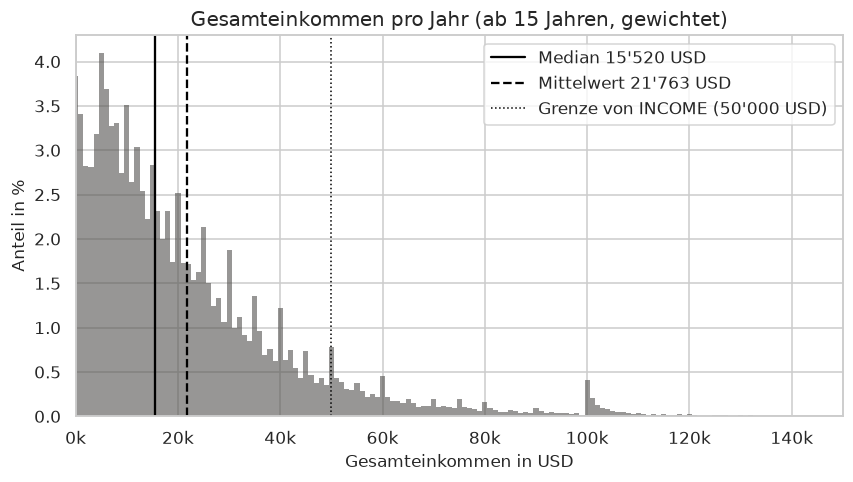

Median: 15520 USD, Mittelwert: 21763 USD
Ohne Einkommen (genau 0) ab 15:   8.1 %
Über 50'000 USD:                  9.1 %
Genau ein Vielfaches von 1'000:   16.7 %
Die obersten 10 % (ab 48000 USD) haben 33.0% des gesamten Einkommens.


In [6]:
einkommen = ab15[ab15["TOTAL_INCOME"] > 0]
median = gewichtetes_quantil(einkommen["TOTAL_INCOME"], einkommen["WEIGHT"], 0.5)
mittelwert = np.average(einkommen["TOTAL_INCOME"], weights=einkommen["WEIGHT"])
print(f"Histogramm: Personen ab 15 mit Einkommen > 0, {len(einkommen)} von {len(ab15)} Zeilen. "
      f"Gezeigt bis 150'000 USD, {(einkommen['TOTAL_INCOME'] > 150000).sum()} Werte liegen darüber.")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=einkommen, x="TOTAL_INCOME", weights="WEIGHT", stat="percent",
             binwidth=1000, binrange=(-500, 150500), color=FARBE_NEUTRAL, alpha=0.6, linewidth=0, ax=ax)
ax.axvline(median, color="black", linewidth=1.5, label=f"Median {median:,.0f} USD".replace(",", "'"))
ax.axvline(mittelwert, color="black", linewidth=1.5, linestyle="--", label=f"Mittelwert {mittelwert:,.0f} USD".replace(",", "'"))
ax.axvline(50000, color="black", linewidth=1, linestyle=":", label="Grenze von INCOME (50'000 USD)")
ax.set_xlim(0, 150000)
ax.xaxis.set_major_formatter(lambda x, pos: f"{x / 1000:.0f}k")
ax.set_title("Gesamteinkommen pro Jahr (ab 15 Jahren, gewichtet)")
ax.set_xlabel("Gesamteinkommen in USD")
ax.set_ylabel("Anteil in %")
ax.legend()
plt.show()

w = einkommen["WEIGHT"]
print(f"Median: {median:.0f} USD, Mittelwert: {mittelwert:.0f} USD")
print(f"Ohne Einkommen (genau 0) ab 15:   {gewichteter_anteil(ab15['TOTAL_INCOME'] == 0, ab15['WEIGHT']):.1f} %")
print(f"Über 50'000 USD:                  {gewichteter_anteil(einkommen['TOTAL_INCOME'] > 50000, w):.1f} %")
print(f"Genau ein Vielfaches von 1'000:   {gewichteter_anteil(einkommen['TOTAL_INCOME'] % 1000 == 0, w):.1f} %")
grenze = gewichtetes_quantil(einkommen["TOTAL_INCOME"], w, 0.9)
summe = einkommen["TOTAL_INCOME"] * w
print(f"Die obersten 10 % (ab {grenze:.0f} USD) haben {summe[einkommen['TOTAL_INCOME'] >= grenze].sum() / summe.sum():.1%} des gesamten Einkommens.")

**Erkenntnis:**
- Die Verteilung ist stark **rechtsschief**: Der Median liegt bei 15'520 USD, der Mittelwert bei 21'763 USD. Wenige hohe Einkommen ziehen den Mittelwert nach oben, deshalb berichten wir ab hier Mediane (VL02).
- Die Grenze von 50'000 USD liegt weit rechts: Nur 9.1 % der Personen mit Einkommen liegen darüber. Die alte Spalte `INCOME` hat also vor allem die oberste Gruppe von allen anderen getrennt.
- Die obersten 10 % haben **ein Drittel** des gesamten Einkommens.
- Die Spitzen bei runden Beträgen (10'000, 15'000, 20'000 USD usw.) sind **Heaping** (VL01): Viele Befragte nennen einen gerundeten Betrag.

### 1.2 Stadt oder Land: Haushaltseinkommen auf log-Skala

`METRO` sagt, ob eine Person in einer Metropolregion wohnt. Wir vergleichen das Einkommen des ganzen Haushalts (`HOUSEHOLD_INCOME`), weil es für den Lebensstandard zählt. Jede Person zählt dabei mit dem Einkommen ihres Haushalts. Auf der log-Skala ist jeder Schritt ein Faktor 10, so sehen wir kleine und grosse Einkommen gleichzeitig. Pro Gruppe zeigen wir Prozente, weil die Gruppen sehr unterschiedlich gross sind.

Histogramm: Personen mit Haushaltseinkommen > 0 und bekanntem Wohnort, 184158 Zeilen.


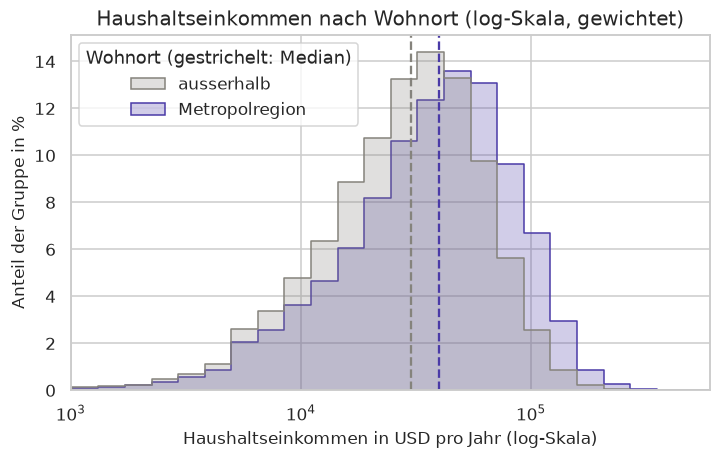

         Metropolregion  ausserhalb
Q(0.1)          10400.0      8991.0
Q(0.25)         21024.0     16650.0
Median          39672.0     30193.0
Q(0.75)         64716.0     48224.0
Q(0.9)          96116.0     70000.0
Unter der Armutsgrenze (Metropolregion): 13.9 %
Unter der Armutsgrenze (ausserhalb): 16.4 %


In [7]:
WOHNORT = {"Metropolitan area": "Metropolregion", "Outside metropolitan area": "ausserhalb"}
haushalte = daten[(daten["HOUSEHOLD_INCOME"] > 0) & daten["METRO"].isin(WOHNORT)].copy()
haushalte["WOHNORT"] = haushalte["METRO"].map(WOHNORT)
farben_wohnort = {"Metropolregion": FARBE_STADT, "ausserhalb": FARBE_LAND}
print(f"Histogramm: Personen mit Haushaltseinkommen > 0 und bekanntem Wohnort, {len(haushalte)} Zeilen.")

fig, ax = plt.subplots()
sns.histplot(data=haushalte, x="HOUSEHOLD_INCOME", hue="WOHNORT", weights="WEIGHT", log_scale=True,
             bins=50, stat="percent", common_norm=False, element="step",
             hue_order=["ausserhalb", "Metropolregion"], palette=farben_wohnort, ax=ax)
quantile = {}
for wohnort, d in haushalte.groupby("WOHNORT"):
    quantile[wohnort] = [gewichtetes_quantil(d["HOUSEHOLD_INCOME"], d["WEIGHT"], p) for p in (0.1, 0.25, 0.5, 0.75, 0.9)]
    ax.axvline(quantile[wohnort][2], color=farben_wohnort[wohnort], linestyle="--", linewidth=1.5)
ax.set_xlim(1000, 600000)
ax.set_title("Haushaltseinkommen nach Wohnort (log-Skala, gewichtet)")
ax.set_xlabel("Haushaltseinkommen in USD pro Jahr (log-Skala)")
ax.set_ylabel("Anteil der Gruppe in %")
sns.move_legend(ax, "upper left", title="Wohnort (gestrichelt: Median)")
plt.show()

print(pd.DataFrame(quantile, index=["Q(0.1)", "Q(0.25)", "Median", "Q(0.75)", "Q(0.9)"]).round(0))
for wohnort, d in haushalte[haushalte["POVERTY_LEVEL"].notna()].groupby("WOHNORT"):
    print(f"Unter der Armutsgrenze ({wohnort}): {gewichteter_anteil(d['POVERTY_LEVEL'] == 'Below poverty line', d['WEIGHT']):.1f} %")

**Erkenntnis:**
- Auf der log-Skala sehen beide Verteilungen fast symmetrisch aus, auf der normalen Skala wären sie stark rechtsschief (wie in Plot 1).
- Die Verteilung der Metropolregionen ist **als Ganzes nach rechts verschoben**: Der Median liegt bei 39'672 gegen 30'193 USD, beim 90-%-Quantil sind es 96'116 gegen 70'000 USD. Ausserhalb der Metropolregionen hat man also in fast jedem Bereich der Verteilung weniger.
- Trotzdem ist die Armutsquote ausserhalb nur wenig höher (16.4 % gegen 13.9 %). Ein Grund könnte sein, dass die Armutsgrenze in den USA überall gleich hoch ist, obwohl das Leben auf dem Land meist günstiger ist.

### 1.3 Die Bundesstaaten: reiche und arme Staaten

Jetzt fassen wir die Personen pro Bundesstaat (`STATE`) zusammen: Median des Haushaltseinkommens und Anteil der Personen unter der Armutsgrenze. Jeder Punkt ist ein Staat, die Grösse zeigt die Anzahl Personen im Datensatz.

Scatterplot: 51 Staaten (inkl. District of Columbia), 188690 Personen. Pro Staat 955 bis 17705 Personen.


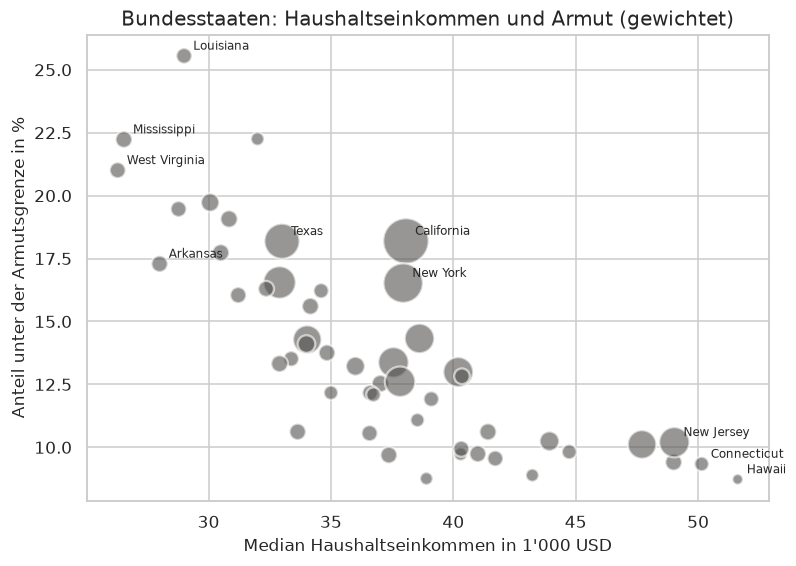

               median_haushalt  armut_%       n
STATE                                          
West Virginia          26287.0     21.0  2156.0
Mississippi            26540.0     22.2  2340.0
Arkansas               28000.0     17.3  2275.0
New Jersey             49028.0     10.2  7828.0
Connecticut            50146.0      9.3  1778.0
Hawaii                 51616.0      8.7   955.0
Meiste Armut: Louisiana (25.6 %)

Korrelation über die Staaten (Vorschau auf VL04): r = -0.79


In [8]:
mit_staat = daten[daten["STATE"].notna() & daten["HOUSEHOLD_INCOME"].notna() & daten["POVERTY_LEVEL"].notna()]
staaten = mit_staat.groupby("STATE").apply(lambda d: pd.Series({
    "median_haushalt": gewichtetes_quantil(d["HOUSEHOLD_INCOME"], d["WEIGHT"], 0.5),
    "armut_%": gewichteter_anteil(d["POVERTY_LEVEL"] == "Below poverty line", d["WEIGHT"]),
    "n": len(d),
}))
print(f"Scatterplot: {len(staaten)} Staaten (inkl. District of Columbia), {len(mit_staat)} Personen. "
      f"Pro Staat {staaten['n'].min():.0f} bis {staaten['n'].max():.0f} Personen.")

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(staaten["median_haushalt"] / 1000, staaten["armut_%"], s=staaten["n"] / 20,
           color=FARBE_NEUTRAL, alpha=0.6, edgecolor="white", linewidth=1.5)
# Beschriftet werden die drei ärmsten und reichsten Staaten, die drei grössten und der mit der meisten Armut
sortiert = staaten.sort_values("median_haushalt")
beschriften = list(sortiert.index[:3]) + list(sortiert.index[-3:]) + list(staaten["n"].nlargest(3).index) + [staaten["armut_%"].idxmax()]
for staat in dict.fromkeys(beschriften):
    ax.annotate(staat, (staaten.loc[staat, "median_haushalt"] / 1000, staaten.loc[staat, "armut_%"]),
                xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.set_title("Bundesstaaten: Haushaltseinkommen und Armut (gewichtet)")
ax.set_xlabel("Median Haushaltseinkommen in 1'000 USD")
ax.set_ylabel("Anteil unter der Armutsgrenze in %")
plt.show()

print(sortiert[["median_haushalt", "armut_%", "n"]].iloc[[0, 1, 2, -3, -2, -1]].round(1))
print(f"Meiste Armut: {staaten['armut_%'].idxmax()} ({staaten['armut_%'].max():.1f} %)")
print(f"\nKorrelation über die Staaten (Vorschau auf VL04): r = {np.corrcoef(staaten['median_haushalt'], staaten['armut_%'])[0, 1]:.2f}")

**Erkenntnis:**
- Zwischen den Staaten liegen grosse Unterschiede: Im Median hat ein Haushalt in **West Virginia** 26'287 USD, in **Hawaii** 51'616 USD, also fast das Doppelte. Die ärmsten Staaten liegen alle im Süden (West Virginia, Mississippi, Arkansas), die reichsten im Nordosten (New Jersey, Connecticut) und in Hawaii. Am meisten Armut gibt es in Louisiana (25.6 %).
- Je höher das typische Einkommen eines Staats, desto weniger Armut: Die Punkte fallen deutlich von links oben nach rechts unten (r = −0.79). Wie man so einen Zusammenhang misst, ist Thema von VL04.
- Ein Punkt ist hier ein ganzer Staat. Daraus folgt nicht, dass jede Person in einem reichen Staat seltener arm ist. Diesen Fehlschluss von Gruppen auf Personen (ökologischer Fehlschluss) sollten wir in der Präsentation vermeiden.

### 1.4 Wer ist arm?

`POVERTY_LEVEL` vergleicht das Einkommen der Familie mit der offiziellen Armutsgrenze, die von der Grösse der Familie abhängt. Links der Anteil unter der Armutsgrenze nach Alter, rechts nur Kinder unter 18, nach den Eltern im Haushalt (`PARENTS_PRESENT`).

Links: alle Personen mit Armutsstufe, 195334 Zeilen. Rechts: Kinder unter 18, 51177 Zeilen.


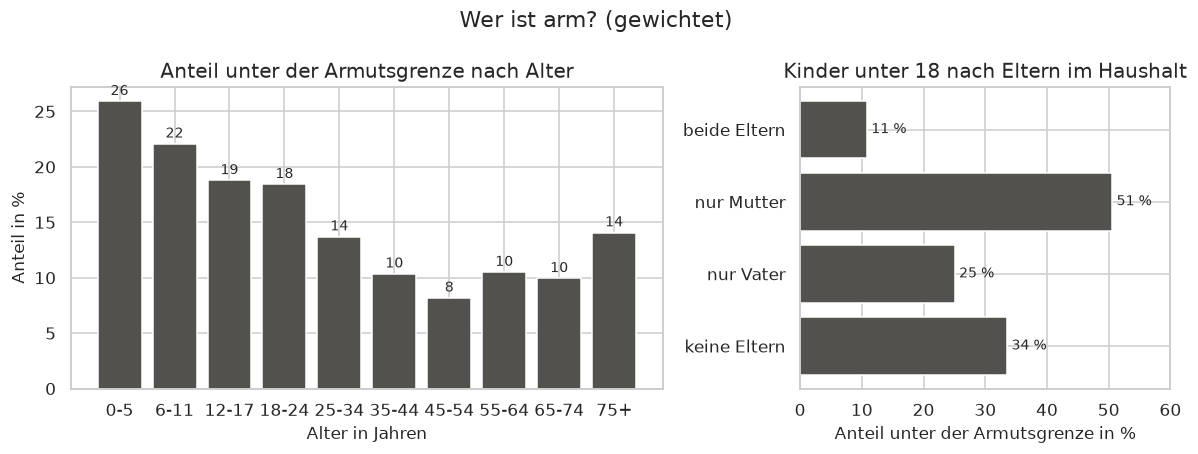

Gesamt unter der Armutsgrenze: 14.7 %
ALTERSGRUPPE
0-5      25.9
6-11     22.1
12-17    18.8
18-24    18.4
25-34    13.7
35-44    10.3
45-54     8.2
55-64    10.5
65-74     9.9
75+      14.1
PARENTS_PRESENT
beide Eltern    10.8
nur Mutter      50.5
nur Vater       25.0
keine Eltern    33.5
PARENTS_PRESENT
beide Eltern    36066
nur Mutter      11727
nur Vater        1735
keine Eltern     1649
Name: count, dtype: int64


In [9]:
armut = daten[daten["POVERTY_LEVEL"].notna()].copy()
armut["ARM"] = armut["POVERTY_LEVEL"] == "Below poverty line"
armut["ALTERSGRUPPE"] = pd.cut(armut["AGE"], bins=[-1, 5, 11, 17, 24, 34, 44, 54, 64, 74, 90],
                               labels=["0-5", "6-11", "12-17", "18-24", "25-34", "35-44", "45-54", "55-64", "65-74", "75+"])
nach_alter = armut.groupby("ALTERSGRUPPE", observed=True).apply(lambda d: gewichteter_anteil(d["ARM"], d["WEIGHT"]))

ELTERN = {"Both parents present": "beide Eltern", "Mother only present": "nur Mutter",
          "Father only present": "nur Vater", "Neither parent present": "keine Eltern"}
kinder = armut[(armut["AGE"] < 18) & armut["PARENTS_PRESENT"].isin(ELTERN)]
nach_eltern = kinder.groupby("PARENTS_PRESENT").apply(lambda d: gewichteter_anteil(d["ARM"], d["WEIGHT"]))
nach_eltern = nach_eltern.rename(index=ELTERN).loc[list(ELTERN.values())]
print(f"Links: alle Personen mit Armutsstufe, {len(armut)} Zeilen. Rechts: Kinder unter 18, {len(kinder)} Zeilen.")

fig, achsen = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
balken = achsen[0].bar(nach_alter.index.astype(str), nach_alter, color=FARBE_NEUTRAL)
achsen[0].bar_label(balken, fmt="%.0f", padding=2, fontsize=9)
achsen[0].set_title("Anteil unter der Armutsgrenze nach Alter")
achsen[0].set_xlabel("Alter in Jahren")
achsen[0].set_ylabel("Anteil in %")
balken = achsen[1].barh(nach_eltern.index, nach_eltern, color=FARBE_NEUTRAL)
achsen[1].bar_label(balken, fmt="%.0f %%", padding=3, fontsize=9)
achsen[1].invert_yaxis()
achsen[1].set_xlim(0, 60)
achsen[1].set_title("Kinder unter 18 nach Eltern im Haushalt")
achsen[1].set_xlabel("Anteil unter der Armutsgrenze in %")
plt.suptitle("Wer ist arm? (gewichtet)")
plt.tight_layout()
plt.show()

print(f"Gesamt unter der Armutsgrenze: {gewichteter_anteil(armut['ARM'], armut['WEIGHT']):.1f} %")
print(nach_alter.round(1).to_string())
print(nach_eltern.round(1).to_string())
print(kinder["PARENTS_PRESENT"].map(ELTERN).value_counts())

**Erkenntnis:**
- Insgesamt leben 14.7 % unter der Armutsgrenze. Am häufigsten trifft es **Kinder**: Bei den unter 6-Jährigen ist es mehr als jedes vierte Kind (26 %). Mit dem Alter sinkt der Anteil und ist mit 45 bis 54 am tiefsten (8 %). Danach steigt er wieder leicht, bei den über 75-Jährigen auf 14 %.
- Rechts sieht man, woran das bei Kindern hängt: Leben beide Eltern im Haushalt, sind 11 % arm. Lebt nur die **Mutter** im Haushalt, ist es die **Hälfte** (51 %), bei nur dem Vater ein Viertel.
- Das passt zu den folgenden Plots: Wenn Frauen weniger verdienen, trifft das Haushalte mit nur einer Mutter besonders stark.

### 1.5 Wie viel arbeiten Frauen und Männer pro Woche?

`HOURS_PER_WEEK` ist die übliche Arbeitszeit pro Woche im Vorjahr. Wir nehmen alle Personen ab 15, die gearbeitet haben, und zeigen pro Geschlecht Prozente. Ein Balken ist eine Stunde.

Histogramme: Personen ab 15, die gearbeitet haben, 103512 Zeilen. Gezeigt bis 80 Stunden, y-Achse bis 15 %.


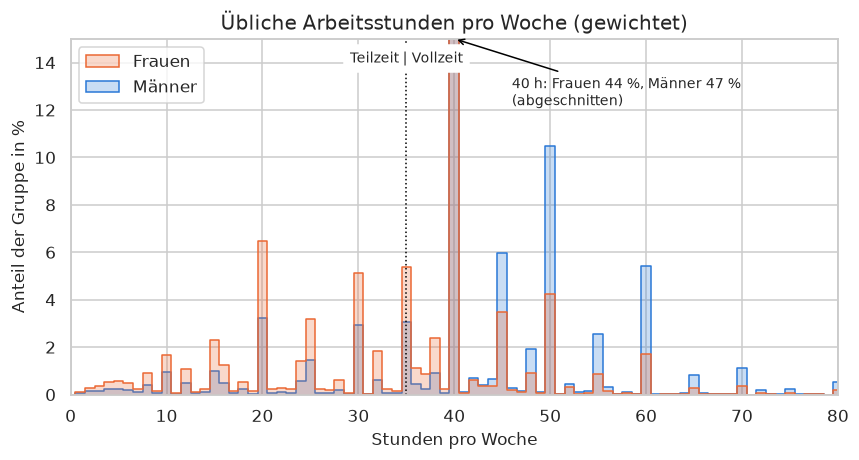

Frauen  genau 40 h: 43.7 %   unter 35 h: 31.3 %   50 h und mehr: 8.8 %   Median: 40 h
Männer  genau 40 h: 47.3 %   unter 35 h: 14.5 %   50 h und mehr: 23.4 %   Median: 40 h


In [10]:
erwerbstaetige = ab15[(ab15["WEEKS_WORKED"] > 0) & (ab15["HOURS_PER_WEEK"] > 0)]
print(f"Histogramme: Personen ab 15, die gearbeitet haben, {len(erwerbstaetige)} Zeilen. Gezeigt bis 80 Stunden, y-Achse bis 15 %.")

fig, ax = plt.subplots(figsize=(9, 4.2))
sns.histplot(data=erwerbstaetige, x="HOURS_PER_WEEK", hue="GESCHLECHT", weights="WEIGHT",
             binwidth=1, binrange=(0.5, 80.5), stat="percent", common_norm=False, element="step",
             hue_order=["Frauen", "Männer"], palette=FARBEN_GESCHLECHT, ax=ax)
ax.axvline(35, color="black", linestyle=":", linewidth=1)
ax.text(35, 14, "Teilzeit | Vollzeit", ha="center", fontsize=9, backgroundcolor="white")
# Die Spitze bei 40 Stunden ist abgeschnitten, sonst sieht man den Rest nicht
ax.set_ylim(0, 15)
ax.annotate("40 h: Frauen 44 %, Männer 47 %\n(abgeschnitten)", xy=(40, 15), xytext=(46, 12.2), fontsize=9,
            arrowprops={"arrowstyle": "->", "color": "black"})
ax.set_xlim(0, 80)
ax.set_title("Übliche Arbeitsstunden pro Woche (gewichtet)")
ax.set_xlabel("Stunden pro Woche")
ax.set_ylabel("Anteil der Gruppe in %")
ax.get_legend().set_title(None)
plt.show()

for geschlecht, d in erwerbstaetige.groupby("GESCHLECHT"):
    h, w = d["HOURS_PER_WEEK"], d["WEIGHT"]
    print(f"{geschlecht:7s} genau 40 h: {gewichteter_anteil(h == 40, w):.1f} %   unter 35 h: {gewichteter_anteil(h < 35, w):.1f} %   "
          f"50 h und mehr: {gewichteter_anteil(h >= 50, w):.1f} %   Median: {gewichtetes_quantil(h, w, 0.5):.0f} h")

**Erkenntnis:**
- Fast die Hälfte gibt **genau 40 Stunden** an. Die riesige Spitze ist die Normalarbeitszeit, dazu kommt Heaping bei runden Werten (20, 30, 45, 50, 60 Stunden).
- Bei den Frauen gibt es einen **zweiten Bereich** unter 35 Stunden: 31 % arbeiten Teilzeit, bei den Männern nur 15 %. Die Verteilung der Frauen ist also eine Mischung aus Teilzeit und Vollzeit (VL02, Modalität).
- Männer arbeiten dafür viel öfter **50 Stunden und mehr** (23 % gegen 9 %). Der Median ist bei beiden 40 Stunden und zeigt diese Unterschiede nicht.

### 1.6 Wird Teilzeit pro Stunde schlechter bezahlt?

Aus Arbeitseinkommen, Wochen und Stunden pro Woche können wir jetzt für alle Erwerbstätigen einen **Stundenlohn** ausrechnen: `EARNINGS / (WEEKS_WORKED × HOURS_PER_WEEK)`. Das ist mehr als der alte `WAGE_PER_HOUR`, den es nur für Personen im Stundenlohn gab. Wir vergleichen Teilzeit (unter 35 Stunden) und Vollzeit, ab 18 Jahren. Der Stripplot zeigt pro Gruppe 300 zufällig gezogene Personen, die schwarzen Striche sind die Mediane aller Personen der Gruppe. Der Plot ist ungewichtet.

Stripplot: je 300 von 99487 Erwerbstätigen ab 18 pro Gruppe. Gezeigt bis 40 USD, 2110 Personen liegen darüber.


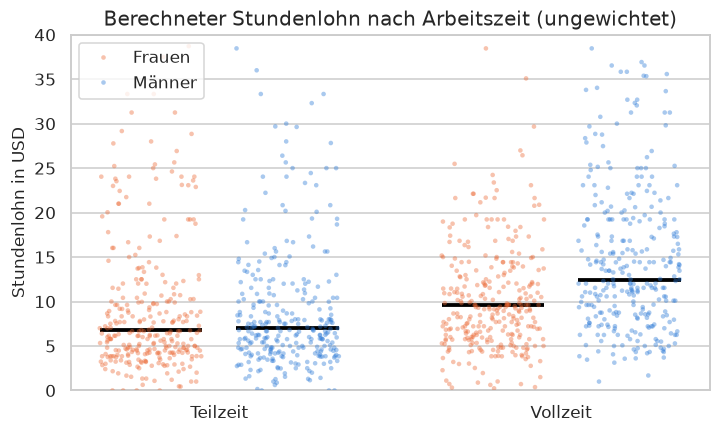

Median Stundenlohn in USD (alle Personen der Gruppe):
GESCHLECHT   Frauen  Männer
ARBEITSZEIT                
Teilzeit       6.79    7.00
Vollzeit       9.62   12.44

Anzahl Personen:
GESCHLECHT   Frauen  Männer
ARBEITSZEIT                
Teilzeit      13989    6149
Vollzeit      33412   45937


In [11]:
stunden = daten[(daten["AGE"] >= 18) & (daten["WEEKS_WORKED"] > 0) & (daten["HOURS_PER_WEEK"] > 0) & (daten["EARNINGS"] > 0)].copy()
stunden["STUNDENLOHN"] = stunden["EARNINGS"] / (stunden["WEEKS_WORKED"] * stunden["HOURS_PER_WEEK"])
stunden["ARBEITSZEIT"] = np.where(stunden["HOURS_PER_WEEK"] < 35, "Teilzeit", "Vollzeit")
gruppen = stunden.groupby(["ARBEITSZEIT", "GESCHLECHT"])
stichprobe = gruppen.sample(n=300, random_state=SEED)
print(f"Stripplot: je 300 von {len(stunden)} Erwerbstätigen ab 18 pro Gruppe. Gezeigt bis 40 USD, "
      f"{(stunden['STUNDENLOHN'] > 40).sum()} Personen liegen darüber.")

fig, ax = plt.subplots()
sns.stripplot(data=stichprobe, x="ARBEITSZEIT", y="STUNDENLOHN", hue="GESCHLECHT", order=["Teilzeit", "Vollzeit"],
              hue_order=["Frauen", "Männer"], palette=FARBEN_GESCHLECHT, dodge=True, jitter=0.3, size=3, alpha=0.4, ax=ax)
mediane = gruppen["STUNDENLOHN"].median()
for x, arbeitszeit in enumerate(["Teilzeit", "Vollzeit"]):
    for versatz, geschlecht in [(-0.2, "Frauen"), (0.2, "Männer")]:
        ax.hlines(mediane[(arbeitszeit, geschlecht)], x + versatz - 0.15, x + versatz + 0.15, color="black", linewidth=2.5)
ax.set_ylim(0, 40)
ax.set_title("Berechneter Stundenlohn nach Arbeitszeit (ungewichtet)")
ax.set_xlabel(None)
ax.set_ylabel("Stundenlohn in USD")
ax.legend(loc="upper left")
plt.show()

print("Median Stundenlohn in USD (alle Personen der Gruppe):")
print(mediane.unstack().round(2))
print("\nAnzahl Personen:")
print(gruppen.size().unstack())

**Erkenntnis:**
- Teilzeit wird **pro Stunde schlechter bezahlt**: Im Median verdienen Frauen bei Teilzeit 6.79 USD pro Stunde, bei Vollzeit 9.62 USD. Bei den Männern sind es 7.00 gegen 12.44 USD. Wer Teilzeit arbeitet, verdient also nicht nur wegen der kürzeren Arbeitszeit weniger.
- Bei Teilzeit verdienen Frauen und Männer pro Stunde fast gleich viel. Der Unterschied zwischen den Geschlechtern zeigt sich vor allem bei **Vollzeit**.
- Die Punktwolken sind sehr breit und nach oben offen. Ein Teil davon sind Messfehler: Der Stundenlohn ist aus drei gerundeten Angaben berechnet (Plot 1 und 5). Deshalb vergleichen wir hier nur Mediane.

### 1.7 Der Lohnunterschied bei Vollzeit: die ECDF

Damit Teilzeit und unterschiedliche Arbeitszeiten den Vergleich nicht verzerren, nehmen wir jetzt nur die Vollzeit-Ganzjahres-Erwerbstätigen. Die ECDF (VL02) zeigt für jedes Arbeitseinkommen (`EARNINGS`), welcher Anteil höchstens so viel verdient.

ECDF: Vollzeit-Ganzjahres-Erwerbstätige, 63186 Zeilen. Gezeigt bis 100'000 USD, 261 Werte liegen darüber.


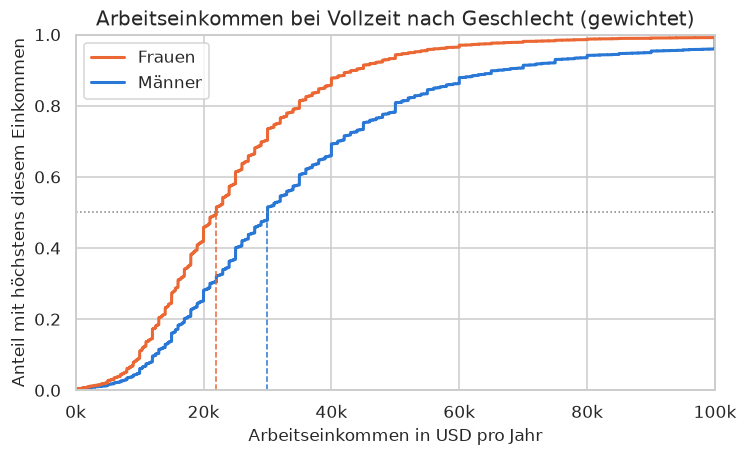

          Frauen   Männer  Frauen pro Dollar Männer
Q(0.1)   10000.0  12500.0                      0.80
Q(0.25)  15000.0  19760.0                      0.76
Median   22000.0  30000.0                      0.73
Q(0.75)  31700.0  45000.0                      0.70
Q(0.9)   44000.0  66500.0                      0.66


In [12]:
print(f"ECDF: Vollzeit-Ganzjahres-Erwerbstätige, {len(vollzeit)} Zeilen. Gezeigt bis 100'000 USD, "
      f"{(vollzeit['EARNINGS'] > 100000).sum()} Werte liegen darüber.")

fig, ax = plt.subplots()
sns.ecdfplot(data=vollzeit, x="EARNINGS", hue="GESCHLECHT", weights="WEIGHT",
             hue_order=["Frauen", "Männer"], palette=FARBEN_GESCHLECHT, linewidth=2, ax=ax)
ax.axhline(0.5, color="gray", linestyle=":", linewidth=1)
quantile = {}
for geschlecht, d in vollzeit.groupby("GESCHLECHT"):
    quantile[geschlecht] = [gewichtetes_quantil(d["EARNINGS"], d["WEIGHT"], p) for p in (0.1, 0.25, 0.5, 0.75, 0.9)]
    ax.plot([quantile[geschlecht][2]] * 2, [0, 0.5], color=FARBEN_GESCHLECHT[geschlecht], linestyle="--", linewidth=1)
ax.set_xlim(0, 100000)
ax.xaxis.set_major_formatter(lambda x, pos: f"{x / 1000:.0f}k")
ax.set_title("Arbeitseinkommen bei Vollzeit nach Geschlecht (gewichtet)")
ax.set_xlabel("Arbeitseinkommen in USD pro Jahr")
ax.set_ylabel("Anteil mit höchstens diesem Einkommen")
ax.get_legend().set_title(None)
plt.show()

tabelle = pd.DataFrame(quantile, index=["Q(0.1)", "Q(0.25)", "Median", "Q(0.75)", "Q(0.9)"])
tabelle["Frauen pro Dollar Männer"] = (tabelle["Frauen"] / tabelle["Männer"]).round(2)
print(tabelle)

**Erkenntnis:**
- Die Kurve der Männer liegt **überall rechts** von der der Frauen. Im Median verdienen Frauen bei Vollzeit 22'000 USD, Männer 30'000 USD. Eine Frau verdient also rund **73 Cents pro Dollar** eines Mannes. Das passt sehr gut zur offiziellen Zahl des Census Bureau für diese Jahre (71.5 % für 1993 und 72.0 % für 1994), ein guter Hinweis, dass unsere Zuordnung in NB01 stimmt.
- Der Unterschied wird nach oben grösser: Beim 90-%-Quantil sind es 44'000 gegen 66'500 USD, also nur noch 66 Cents pro Dollar. Sehr hohe Einkommen sind bei Frauen also besonders selten.
- Weil hier nur Vollzeit-Ganzjahres-Erwerbstätige drin sind, erklärt die Arbeitszeit diesen Unterschied **nicht**.

### 1.8 Wann öffnet sich die Lücke? Das Einkommen über das Berufsleben

Wir rechnen pro Altersgruppe den Median des Arbeitseinkommens bei Vollzeit, getrennt nach Geschlecht. Das Band zeigt die mittleren 50 % (Q(0.25) bis Q(0.75), also den IQR aus VL02).

Linien: Vollzeit-Ganzjahres-Erwerbstätige von 18 bis 64, 61992 Zeilen.


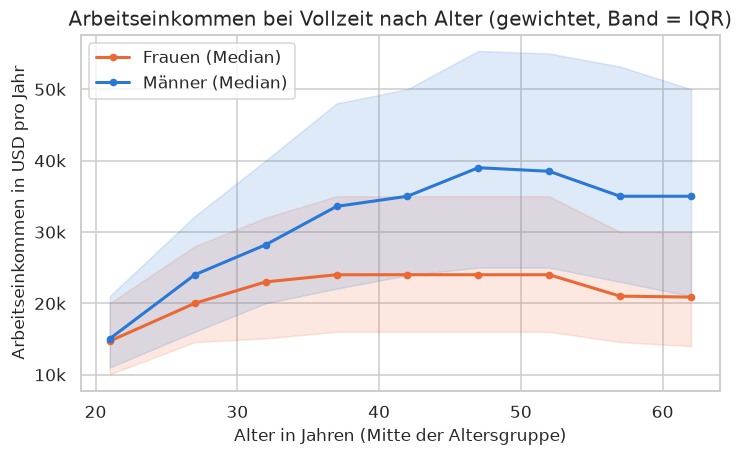

GESCHLECHT     Frauen   Männer  Frauen pro Dollar Männer
ALTERSGRUPPE                                            
21            14700.0  15028.0                      0.98
27            20000.0  24000.0                      0.83
32            23000.0  28200.0                      0.82
37            24000.0  33578.0                      0.71
42            24008.0  35000.0                      0.69
47            24000.0  39000.0                      0.62
52            24000.0  38500.0                      0.62
57            21000.0  35000.0                      0.60
62            20871.0  35000.0                      0.60


In [13]:
vollzeit_18_64 = vollzeit[vollzeit["AGE"].between(18, 64)].copy()
GRENZEN = [17, 24, 29, 34, 39, 44, 49, 54, 59, 64]
MITTE = [21, 27, 32, 37, 42, 47, 52, 57, 62]
vollzeit_18_64["ALTERSGRUPPE"] = pd.cut(vollzeit_18_64["AGE"], bins=GRENZEN, labels=MITTE)
profil = vollzeit_18_64.groupby(["GESCHLECHT", "ALTERSGRUPPE"], observed=True).apply(lambda d: pd.Series({
    p: gewichtetes_quantil(d["EARNINGS"], d["WEIGHT"], q) for p, q in [("Q1", 0.25), ("Median", 0.5), ("Q3", 0.75)]
}))
print(f"Linien: Vollzeit-Ganzjahres-Erwerbstätige von 18 bis 64, {len(vollzeit_18_64)} Zeilen.")

fig, ax = plt.subplots()
for geschlecht, farbe in FARBEN_GESCHLECHT.items():
    d = profil.loc[geschlecht]
    x = d.index.astype(int)
    ax.fill_between(x, d["Q1"], d["Q3"], color=farbe, alpha=0.15)
    ax.plot(x, d["Median"], color=farbe, linewidth=2, marker="o", markersize=4, label=f"{geschlecht} (Median)")
ax.yaxis.set_major_formatter(lambda y, pos: f"{y / 1000:.0f}k")
ax.set_title("Arbeitseinkommen bei Vollzeit nach Alter (gewichtet, Band = IQR)")
ax.set_xlabel("Alter in Jahren (Mitte der Altersgruppe)")
ax.set_ylabel("Arbeitseinkommen in USD pro Jahr")
ax.legend(loc="upper left")
plt.show()

median_tabelle = profil["Median"].unstack(level=0)
median_tabelle["Frauen pro Dollar Männer"] = (median_tabelle["Frauen"] / median_tabelle["Männer"]).round(2)
print(median_tabelle)

**Erkenntnis:**
- Am Anfang des Berufslebens ist der Unterschied klein: Bis 24 Jahre verdienen Frauen bei Vollzeit **98 Cents** pro Dollar der Männer.
- Danach steigt das Einkommen der Männer bis Ende 40 weiter an (Median 39'000 USD). Das der Frauen bleibt ab etwa 35 Jahren bei 24'000 USD stehen. Mit 45 bis 64 Jahren liegen Frauen nur noch bei rund **60 Cents** pro Dollar.
- Das Band der Männer wird mit dem Alter auch viel breiter: Ihre Einkommen gehen weiter auseinander.
- Die Lücke öffnet sich also ab Ende 20 und wird ab 35 deutlich grösser, in den Jahren, in denen oft Kinder kommen. Ob das der Grund ist, können wir mit diesen Daten nicht prüfen. Ausserdem vergleicht der Plot verschiedene Jahrgänge zum gleichen Zeitpunkt und nicht dieselben Personen über ihr Leben.

### 1.9 Hilft Bildung gegen die Lücke?

Wir vergleichen das Arbeitseinkommen bei Vollzeit nach Bildung und Geschlecht, ab 25 Jahren. Die Abschlüsse sind zu sechs Gruppen zusammengefasst. Der Boxplot ist ungewichtet.

Boxplot: Vollzeit-Ganzjahres-Erwerbstätige ab 25, 58447 Zeilen. Gezeigt bis 120'000 USD, 105 Werte liegen darüber.


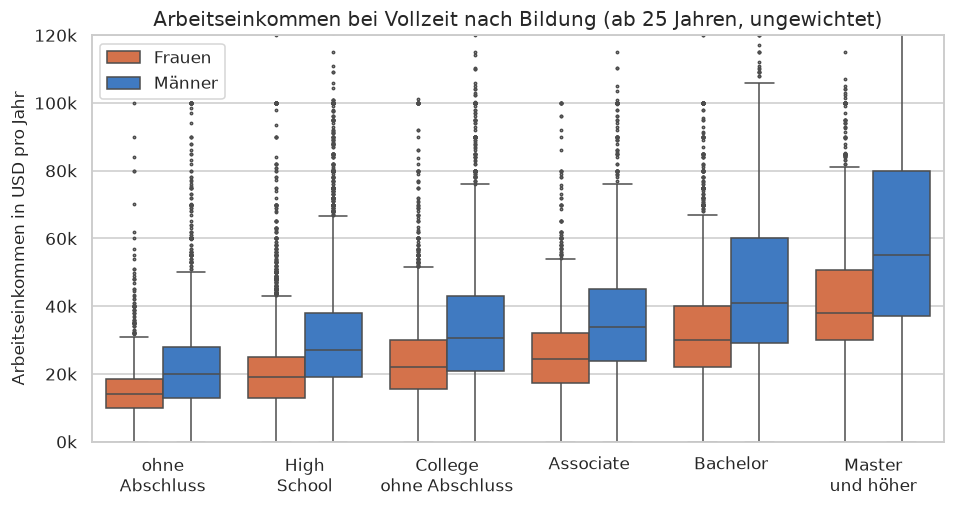

GESCHLECHT               Frauen   Männer  Frauen pro Dollar Männer
BILDUNGSGRUPPE                                                    
ohne Abschluss          14000.0  20000.0                      0.70
High School             19000.0  27000.0                      0.70
College ohne Abschluss  22000.0  30665.0                      0.72
Associate               24500.0  33800.0                      0.72
Bachelor                30000.0  41000.0                      0.73
Master und höher        38000.0  55000.0                      0.69


In [14]:
BILDUNGSGRUPPEN = {
    "High school graduate": "High School",
    "Some college but no degree": "College ohne Abschluss",
    "Associates degree-occup /vocational": "Associate",
    "Associates degree-academic program": "Associate",
    "Bachelors degree(BA AB BS)": "Bachelor",
    "Masters degree(MA MS MEng MEd MSW MBA)": "Master und höher",
    "Prof school degree (MD DDS DVM LLB JD)": "Master und höher",
    "Doctorate degree(PhD EdD)": "Master und höher",
}
REIHENFOLGE = ["ohne Abschluss", "High School", "College ohne Abschluss", "Associate", "Bachelor", "Master und höher"]
vollzeit_25 = vollzeit[vollzeit["AGE"] >= 25].copy()
# Alle Stufen unter High School gelten als "ohne Abschluss"
vollzeit_25["BILDUNGSGRUPPE"] = vollzeit_25["EDUCATION"].astype(str).map(BILDUNGSGRUPPEN).fillna("ohne Abschluss")
print(f"Boxplot: Vollzeit-Ganzjahres-Erwerbstätige ab 25, {len(vollzeit_25)} Zeilen. Gezeigt bis 120'000 USD, "
      f"{(vollzeit_25['EARNINGS'] > 120000).sum()} Werte liegen darüber.")

fig, ax = plt.subplots(figsize=(10, 4.8))
sns.boxplot(data=vollzeit_25, x="BILDUNGSGRUPPE", y="EARNINGS", hue="GESCHLECHT", order=REIHENFOLGE,
            hue_order=["Frauen", "Männer"], palette=FARBEN_GESCHLECHT, fliersize=1.5, ax=ax)
ax.set_ylim(0, 120000)
ax.yaxis.set_major_formatter(lambda y, pos: f"{y / 1000:.0f}k")
ax.set_xticks(range(len(REIHENFOLGE)), [g.replace(" ", "\n", 1) for g in REIHENFOLGE])
ax.set_title("Arbeitseinkommen bei Vollzeit nach Bildung (ab 25 Jahren, ungewichtet)")
ax.set_xlabel(None)
ax.set_ylabel("Arbeitseinkommen in USD pro Jahr")
ax.get_legend().set_title(None)
plt.show()

mediane = vollzeit_25.groupby(["BILDUNGSGRUPPE", "GESCHLECHT"])["EARNINGS"].median().unstack().loc[REIHENFOLGE]
mediane["Frauen pro Dollar Männer"] = (mediane["Frauen"] / mediane["Männer"]).round(2)
print(mediane)

**Erkenntnis:**
- Mehr Bildung bedeutet für beide Geschlechter mehr Einkommen, und die Boxen werden nach oben breiter: Mit mehr Bildung gehen die Einkommen auch weiter auseinander.
- Aber die Lücke bleibt auf **jeder** Bildungsstufe ungefähr gleich gross: Frauen verdienen überall nur 69 bis 73 Cents pro Dollar der Männer.
- Am deutlichsten wird das so: Frauen mit **Bachelor** verdienen im Median 30'000 USD, kaum mehr als Männer mit **High School** (27'000 USD). Frauen mit Master oder höher (38'000 USD) liegen sogar unter Männern mit Bachelor (41'000 USD). Bildung erhöht das Einkommen, schliesst die Lücke aber nicht.

### 1.10 Wie viel trägt wer zum Haushaltseinkommen bei?

Zum Schluss der Blick auf den Haushalt: Wir nehmen verheiratete Personen von 25 bis 64 Jahren, die mit dem Ehepartner zusammenleben, und rechnen, welchen Anteil ihr eigenes Einkommen am Einkommen des ganzen Haushalts hat. Anteile unter 0 oder über 1 (z.B. wegen Verlusten anderer Haushaltsmitglieder) setzen wir auf 0 bzw. 1.

Histogramme: verheiratete Personen von 25 bis 64 mit Haushaltseinkommen > 0, 67537 Zeilen.


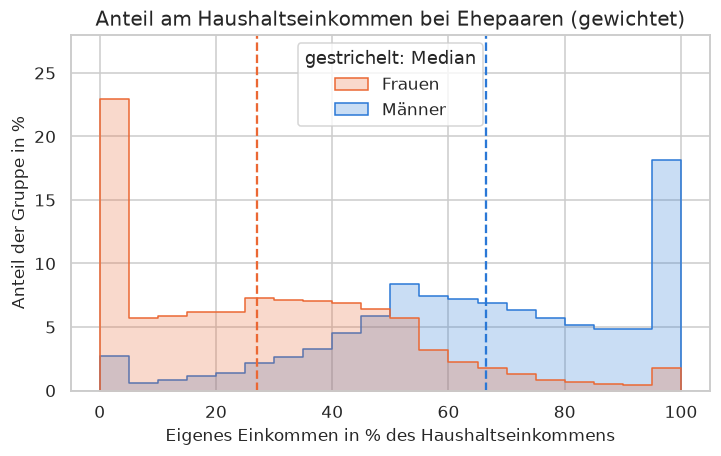

Frauen  Median: 27 %   unter 5 %: 23.0 %   unter 10 %: 28.7 %   über 50 %: 17.3 %   95 % und mehr: 1.8 %
Männer  Median: 66 %   unter 5 %: 2.7 %   unter 10 %: 3.3 %   über 50 %: 73.8 %   95 % und mehr: 18.2 %


In [15]:
paare = daten[(daten["MARITAL_STATUS"] == "Married-civilian spouse present") & daten["AGE"].between(25, 64)
              & (daten["HOUSEHOLD_INCOME"] > 0) & daten["TOTAL_INCOME"].notna()].copy()
paare["ANTEIL"] = (paare["TOTAL_INCOME"] / paare["HOUSEHOLD_INCOME"]).clip(0, 1) * 100
print(f"Histogramme: verheiratete Personen von 25 bis 64 mit Haushaltseinkommen > 0, {len(paare)} Zeilen.")

fig, ax = plt.subplots()
sns.histplot(data=paare, x="ANTEIL", hue="GESCHLECHT", weights="WEIGHT", binwidth=5, binrange=(0, 100),
             stat="percent", common_norm=False, element="step",
             hue_order=["Frauen", "Männer"], palette=FARBEN_GESCHLECHT, ax=ax)
for geschlecht, d in paare.groupby("GESCHLECHT"):
    ax.axvline(gewichtetes_quantil(d["ANTEIL"], d["WEIGHT"], 0.5), color=FARBEN_GESCHLECHT[geschlecht], linestyle="--", linewidth=1.5)
ax.set_title("Anteil am Haushaltseinkommen bei Ehepaaren (gewichtet)")
ax.set_xlabel("Eigenes Einkommen in % des Haushaltseinkommens")
ax.set_ylabel("Anteil der Gruppe in %")
ax.set_ylim(0, 28)  # Platz für die Legende
sns.move_legend(ax, "upper center", title="gestrichelt: Median")
plt.show()

for geschlecht, d in paare.groupby("GESCHLECHT"):
    a, w = d["ANTEIL"], d["WEIGHT"]
    print(f"{geschlecht:7s} Median: {gewichtetes_quantil(a, w, 0.5):.0f} %   unter 5 %: {gewichteter_anteil(a < 5, w):.1f} %   "
          f"unter 10 %: {gewichteter_anteil(a < 10, w):.1f} %   über 50 %: {gewichteter_anteil(a > 50, w):.1f} %   "
          f"95 % und mehr: {gewichteter_anteil(a >= 95, w):.1f} %")

**Erkenntnis:**
- Die beiden Verteilungen sind fast **spiegelbildlich**. Der Median der Männer liegt bei 66 %, der der Frauen bei 27 %. Drei Viertel der Männer tragen mehr als die Hälfte zum Haushaltseinkommen bei, bei den Frauen nur jede sechste.
- Beide Verteilungen sind eine Mischung aus zwei Gruppen (VL02, Modalität): Bei den Frauen hat fast ein Viertel (23 %) weniger als 5 % Anteil, also praktisch kein eigenes Einkommen. Die übrigen verteilen sich fast gleichmässig zwischen 5 und 50 %. Bei den Männern gibt es dafür eine Spitze bei 95 % und mehr: 18 % sind praktisch **Alleinverdiener**, bei den Frauen nur 2 %.
- Das verbindet die Plots: Weniger Arbeitsstunden (Plot 5), tiefere Löhne bei gleicher Arbeitszeit (Plot 7) und die wachsende Lücke ab Ende 20 (Plot 8) führen dazu, dass Frauen im Haushalt meist das kleinere Einkommen haben. Fehlt der Partner, wie bei alleinerziehenden Müttern, steigt das Armutsrisiko stark (Plot 4).

### Die Geschichte in fünf Sätzen

Für die Präsentation lässt sich der Abschnitt so zusammenfassen:
§
1. **Einkommen sind sehr ungleich verteilt.** Der Median liegt bei 15'520 USD, die obersten 10 % haben ein Drittel des gesamten Einkommens (Plot 1).
2. **Wo man wohnt, zählt.** In Metropolregionen und im Nordosten ist das Haushaltseinkommen deutlich höher, im Süden ist die Armut am grössten (Plots 2 und 3).
3. **Armut trifft vor allem Kinder,** besonders die von alleinerziehenden Müttern: Die Hälfte davon lebt unter der Armutsgrenze (Plot 4).
4. **Frauen verdienen bei Vollzeit 73 Cents pro Dollar der Männer.** Die Lücke wächst ab Ende 20, bleibt auf jeder Bildungsstufe bestehen und kommt zur häufigeren, pro Stunde schlechter bezahlten Teilzeit dazu (Plots 5 bis 9).
5. **Im Haushalt tragen Frauen meist den kleineren Teil bei,** im Median 27 % (Plot 10).

Alle Aussagen sind beschreibend. Ob z.B. das Geschlecht den Lohn wirklich beeinflusst, wenn man Beruf, Erfahrung und Arbeitszeit gleichzeitig berücksichtigt, können wir erst mit Regression prüfen (VL10 und VL11).